<div style="font-family:'Times New Roman',Times,serif;color:#000000">
<div style="font-size:13px;letter-spacing:2px">NATIONAL UNIVERSITY OF SCIENCES AND TECHNOLOGY &nbsp;&middot;&nbsp; SEECS</div>
<div style="font-size:13px;letter-spacing:1px;font-weight:bold">CS-320 &nbsp;&middot;&nbsp; ARTIFICIAL NEURAL NETWORKS &amp; DEEP LEARNING &nbsp;&middot;&nbsp; BSAI</div>
<div style="font-size:28px;font-weight:bold;margin-top:6px">Lab 6 &mdash; Backpropagation from Scratch: Training a Complete MLP</div>
<div style="font-size:15px;margin-top:4px">3 hours &nbsp;&middot;&nbsp; CLO 1, CLO 4</div>
</div>

---

<div style="font-family:'Times New Roman',Times,serif;color:#000000;font-size:16px">

**Course Instructor:** Dr. Faisal Shafait &nbsp;|&nbsp; **Lab Engineer:** Ms Areeba Rameen &nbsp;|&nbsp; **Student name / CMS ID:** Muhammad Sikandar Hussain / 502808

### What this lab is for

In the last three labs you built the separate pieces of a learning machine: the forward pass
(Lab 3), the loss function (Lab 4), and the gradient descent update rule (Lab 5). One piece is
still missing. Gradient descent needs the gradient of the loss with respect to **every weight**
in the network, including weights in the hidden layer that touch the loss only indirectly.
The algorithm that computes all of those gradients efficiently is called **backpropagation**.

In this lab you will work out backpropagation by hand on a very small network, turn it into
matrix code for a two-layer network, check it against a numerical gradient, and then use it to
train a complete network end to end. By the end, a network that could not be trained by hand-set
weights in Lab 2 will learn XOR by itself.

**Submission.** Restart the kernel, run everything top to bottom, save, and rename to
`Lab6_<yourCMSID>.ipynb` before uploading to LMS.

</div>

## Background: What is backpropagation?

**The problem.** Gradient descent says: new_weight = old_weight - learning_rate x gradient.
For a straight line (Lab 5) the gradient of each parameter was a short formula. In a network
with a hidden layer, a first-layer weight does not touch the loss directly. It changes a
hidden value, which changes the output, which changes the loss. We need a way to measure the
effect of a weight on the loss through this whole chain.

**The chain rule, in simple words.** If A affects B, and B affects C, then the effect of A on
C is (effect of A on B) multiplied by (effect of B on C). Think of two gears: if the first gear
makes the second turn 2 times, and the second makes the third turn 3 times, then one turn of
the first gear makes the third turn 2 x 3 = 6 times. Backpropagation is nothing more than
this multiplication, applied one layer at a time.

**Forward pass and backward pass.**

- The **forward pass** goes from the input to the loss and computes every value on the way.
  These values are stored (a "cache"), because the backward pass needs them again.
- The **backward pass** starts at the loss and walks back, one layer at a time, towards the
  input. At each layer it does two jobs: it computes the gradient for that layer's weights,
  and it passes the error one step further back.

**The network used in this lab** has two layers: `[2, h, 1]` (2 inputs, h hidden units, 1 output),
sigmoid in both layers, and binary cross-entropy loss. In the formulas below, a leading `d`
means "gradient of the loss with respect to", and `m` is the number of examples.

```
Forward                              Backward
Z1 = X  @ W1.T + b1                  dZ2 = (A2 - y) / m
A1 = sigmoid(Z1)                     dW2 = dZ2.T @ A1
Z2 = A1 @ W2.T + b2                  db2 = sum of dZ2 over the rows
A2 = sigmoid(Z2)                     dA1 = dZ2 @ W2
loss = BCE(y, A2)                    dZ1 = dA1 * A1 * (1 - A1)
                                     dW1 = dZ1.T @ X
                                     db1 = sum of dZ1 over the rows
```

**Reading the backward column line by line.**

1. `dZ2 = (A2 - y) / m` is the error at the output. This is the result you found in Lab 4 for
   cross-entropy with a sigmoid. It is divided by `m` because the loss is an average.
2. `dW2 = dZ2.T @ A1`: the gradient of a weight is (error at its output) x (the input it multiplied).
3. `dA1 = dZ2 @ W2`: the output error is sent back through the weights to the hidden layer.
4. `dZ1 = dA1 * A1 * (1 - A1)`: the error passes back through the sigmoid. `A1 * (1 - A1)` is
   the sigmoid derivative from Lab 3, and it is never larger than 0.25.
5. `dW1 = dZ1.T @ X` follows exactly the same pattern as step 2, one layer earlier.

**Shapes (check these every time).** Every gradient must have the same shape as the thing it
belongs to: `dW1` like `W1`, `db1` like `b1`, `dW2` like `W2`, `db2` like `b2`.

**Why gradient checking?** A mistake in a backward pass does not crash the program. The network
just trains badly. Comparing against a numerical gradient (Lab 3, Task 2) is the one reliable
way to catch such a mistake.


## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.datasets import make_moons
np.set_printoptions(precision=4, suppress=True)
print("ready")


ready


## Task 1 &mdash; The forward pass, with a memory

> **Concept.** The backward pass needs several values that were computed during the forward
> pass (the input `X`, the hidden activations `A1` and the output `A2`). So the forward
> function does not only return the prediction: it also returns a **cache**, a small tuple
> holding those values, for the backward function to use later.

The helper functions `sigmoid`, `bce` and `init_params` are provided (they are the same as in
Labs 3 and 4). The XOR dataset is also provided; note that `y_xor` has shape `(4, 1)`, a column,
so that it matches the shape of the network output.

**Task 1.1.** Run the helper cell and read the printed shapes.

**Task 1.2.** Implement `forward(X, W1, b1, W2, b2)`. It must return `A2` and
`cache = (X, A1, A2)`. Use the same convention as Lab 3: `Z = A_prev @ W.T + b`.

**Task 1.3.** Run it on XOR with the initial parameters and print the output and the loss.
An untrained network has not learned anything yet, so all four outputs will be similar to each other and the loss will be around 0.7.


In [2]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def bce(y_true, p_pred):
    p = np.clip(p_pred, 1e-12, 1 - 1e-12)
    return -np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

def init_params(sizes, seed=0):
    # sizes = [n_in, n_hidden, n_out]; small random weights, zero biases
    rng = np.random.default_rng(seed)
    W1 = rng.normal(0, 1, (sizes[1], sizes[0])) * 0.5
    b1 = np.zeros(sizes[1])
    W2 = rng.normal(0, 1, (sizes[2], sizes[1])) * 0.5
    b2 = np.zeros(sizes[2])
    return W1, b1, W2, b2

X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_xor = np.array([[0], [1], [1], [0]], dtype=float)      # shape (4, 1)

W1, b1, W2, b2 = init_params([2, 4, 1], seed=0)
print("X_xor", X_xor.shape, " y_xor", y_xor.shape)
print("W1", W1.shape, " b1", b1.shape, " W2", W2.shape, " b2", b2.shape)


X_xor (4, 2)  y_xor (4, 1)
W1 (4, 2)  b1 (4,)  W2 (1, 4)  b2 (1,)


In [3]:
def forward(X, W1, b1, W2, b2):
    # Task 1.2 — Z1, A1, Z2, A2, then return A2 and the cache (X, A1, A2)
    Z1 = X @ W1.T + b1
    A1 = sigmoid(Z1)
    Z2 = A1 @ W2.T + b2
    A2 = sigmoid(Z2)
    cache = (X, A1, A2)
    return A2, cache

A2, cache = forward(X_xor, W1, b1, W2, b2)
print("output A2:\n", A2)
print("loss:", bce(y_xor, A2))
assert A2.shape == (4, 1)

# Task 1 answers:
# Q1 (why does forward() store X, A1 and A2 in the cache):
# Answer: The backward pass (backpropagation) applies the chain rule layer by layer and directly depends
# on intermediate quantities computed during the forward pass:
# 1. X is needed to compute dW1 = dZ1.T @ X
# 2. A1 is needed to compute dW2 = dZ2.T @ A1 and the sigmoid derivative factor dZ1 = dA1 * A1 * (1 - A1)
# 3. A2 is needed to compute the output error dZ2 = (A2 - y) / m
# Caching them avoids redundant recomputation and cleanly decouples forward and backward passes.
#
# Q2 (what shape does A2 have, and why must y_xor have the same shape):
# Answer: A2 has shape (4, 1), representing predictions for m=4 examples across 1 output unit.
# y_xor must have the exact same shape (4, 1) (a 2D column vector, rather than a 1D vector of shape (4,))
# so that element-wise operations like (A2 - y) and the binary cross-entropy calculation operate
# row-by-row without unintended NumPy broadcasting mismatches (e.g. subtracting shape (4,) from (4, 1)
# would inadvertently produce a (4, 4) matrix).

output A2:
 [[0.3457]
 [0.3426]
 [0.3386]
 [0.3354]]
loss: 0.7467800471165728


## Task 2 &mdash; Backpropagation by hand on a tiny network

> **Concept.** Before using matrices, look at the smallest possible network: one input, one
> hidden neuron, one output neuron, so every value is a single number. The formulas are the
> same as in the Background section, only without matrices:
>
> ```
> Forward:   z1 = w1*x + b1     a1 = sigmoid(z1)     z2 = w2*a1 + b2     a2 = sigmoid(z2)
> Loss:      L = -[ y*log(a2) + (1-y)*log(1-a2) ]
> Backward:  dz2 = a2 - y       dw2 = dz2 * a1       db2 = dz2
>            da1 = dz2 * w2     dz1 = da1 * a1 * (1 - a1)
>            dw1 = dz1 * x      db1 = dz1
> ```

Use: `x = 1`, `y = 1`, `w1 = 0.5`, `b1 = 0`, `w2 = 0.8`, `b2 = 0`.

**Task 2.1.** By hand (calculator, 4 decimal places), compute the forward values and the loss.

| z1 | a1 | z2 | a2 | Loss |
|:---:|:---:|:---:|:---:|:---:|
| 0.5000 | 0.6225 | 0.4980 | 0.6220 | 0.4748 |

**Task 2.2.** By hand, compute the backward values.

| dz2 | dw2 | db2 | da1 | dz1 | dw1 | db1 |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| -0.3780 | -0.2353 | -0.3780 | -0.3024 | -0.0711 | -0.0711 | -0.0711 |

**Task 2.3.** Write the same computation in code with plain numbers and confirm it matches
your hand-worked tables. Then take **one** gradient descent step with `lr = 1.0` on all four
parameters, recompute the loss, and confirm that it went down.

In [4]:
x, y = 1.0, 1.0
w1, b1_s, w2, b2_s = 0.5, 0.0, 0.8, 0.0

# Task 2.3 — forward: z1, a1, z2, a2, loss
z1 = w1 * x + b1_s
a1 = 1 / (1 + np.exp(-z1))
z2 = w2 * a1 + b2_s
a2 = 1 / (1 + np.exp(-z2))
loss = -(y * np.log(a2) + (1 - y) * np.log(1 - a2))

print(f"Forward:  z1 = {z1:.4f}, a1 = {a1:.4f}, z2 = {z2:.4f}, a2 = {a2:.4f}, Loss = {loss:.4f}")

# Task 2.3 — backward: dz2, dw2, db2, da1, dz1, dw1, db1
dz2 = a2 - y
dw2 = dz2 * a1
db2 = dz2
da1 = dz2 * w2
dz1 = da1 * a1 * (1 - a1)
dw1 = dz1 * x
db1 = dz1

print(f"Backward: dz2 = {dz2:.4f}, dw2 = {dw2:.4f}, db2 = {db2:.4f}, da1 = {da1:.4f}, dz1 = {dz1:.4f}, dw1 = {dw1:.4f}, db1 = {db1:.4f}")

# Task 2.3 — one step with lr = 1.0, then recompute the loss and compare
lr = 1.0
w1_new = w1 - lr * dw1
b1_s_new = b1_s - lr * db1
w2_new = w2 - lr * dw2
b2_s_new = b2_s - lr * db2

z1_new = w1_new * x + b1_s_new
a1_new = 1 / (1 + np.exp(-z1_new))
z2_new = w2_new * a1_new + b2_s_new
a2_new = 1 / (1 + np.exp(-z2_new))
loss_new = -(y * np.log(a2_new) + (1 - y) * np.log(1 - a2_new))

print(f"Updated parameters: w1={w1_new:.4f}, b1={b1_s_new:.4f}, w2={w2_new:.4f}, b2={b2_s_new:.4f}")
print(f"Initial loss: {loss:.4f} -> Updated loss after 1 step: {loss_new:.4f} (decreased by {loss - loss_new:.4f})")

# Task 2 answers:
# Q1 (dw2 is negative: what does that tell you to do to w2, and why):
# Answer: Since dw2 = dL/dw2 is negative (-0.2353), the slope of the loss with respect to w2 is negative,
# meaning increasing w2 will decrease the loss. Under gradient descent (w2_new = w2 - lr * dw2), subtracting
# a negative number adds a positive quantity, effectively increasing w2. An increased w2 produces a larger z2,
# which pushes a2 = sigmoid(z2) closer to the true target y = 1, thereby lowering the cross-entropy loss.
#
# Q2 (compare the size of dz1 with dz2: why is the gradient smaller after passing back
#     through the sigmoid? connect to Lab 3, Task 3):
# Answer: dz1 (-0.0711) is much smaller in magnitude than dz2 (-0.3780). When the error propagates back through
# the hidden unit's sigmoid activation, it gets multiplied by the sigmoid derivative factor a1 * (1 - a1) = sigma'(z1).
# In Lab 3, Task 3, we showed that the maximum value of the sigmoid derivative is only 0.25 (which occurs at z=0),
# and it is strictly smaller everywhere else (here, 0.6225 * (1 - 0.6225) ≈ 0.2350). Multiplying by a factor <= 0.25
# always contracts the gradient, which is the underlying mathematical cause of the vanishing gradient problem in deep networks.

Forward:  z1 = 0.5000, a1 = 0.6225, z2 = 0.4980, a2 = 0.6220, Loss = 0.4748
Backward: dz2 = -0.3780, dw2 = -0.2353, db2 = -0.3780, da1 = -0.3024, dz1 = -0.0711, dw1 = -0.0711, db1 = -0.0711
Updated parameters: w1=0.5711, b1=0.0711, w2=1.0353, b2=0.3780
Initial loss: 0.4748 -> Updated loss after 1 step: 0.2984 (decreased by 0.1764)


## Task 3 &mdash; The backward pass for the full network

> **Concept.** The full network does exactly what Task 2 did, but for all `m` examples and
> all weights at once, using matrix products. The seven backward lines in the Background
> section are the whole algorithm. The only thing to be careful about is shapes.

**Task 3.1.** Implement `backward(y, cache, W2)` returning `dW1, db1, dW2, db2`. Unpack the
cache as `X, A1, A2 = cache`, and use the formulas from the Background section.
For `db1` and `db2`, sum over the rows: `np.sum(..., axis=0)`.

**Task 3.2.** Add shape assertions inside `backward`: each gradient must have the same shape
as the parameter it belongs to. (An assertion that fires is a bug caught in one second.)

**Task 3.3.** Run it on the XOR cache from Task 1 and print the shape of every gradient.


In [5]:
def backward(y, cache, W2):
    X, A1, A2 = cache
    m = X.shape[0]
    # Task 3.1 — dZ2, dW2, db2, dA1, dZ1, dW1, db1 (formulas in the Background section)
    dZ2 = (A2 - y) / m
    dW2 = dZ2.T @ A1
    db2 = np.sum(dZ2, axis=0)
    dA1 = dZ2 @ W2
    dZ1 = dA1 * A1 * (1 - A1)
    dW1 = dZ1.T @ X
    db1 = np.sum(dZ1, axis=0)

    # Task 3.2 — assert each gradient has the same shape as its parameter
    assert dW1.shape == (A1.shape[1], X.shape[1]), f"dW1 shape mismatch: {dW1.shape} vs {(A1.shape[1], X.shape[1])}"
    assert db1.shape == (A1.shape[1],), f"db1 shape mismatch: {db1.shape} vs {(A1.shape[1],)}"
    assert dW2.shape == (A2.shape[1], A1.shape[1]), f"dW2 shape mismatch: {dW2.shape} vs {(A2.shape[1], A1.shape[1])}"
    assert db2.shape == (A2.shape[1],), f"db2 shape mismatch: {db2.shape} vs {(A2.shape[1],)}"

    return dW1, db1, dW2, db2

# Task 3.3 — Run on XOR cache and print gradient shapes
dW1, db1, dW2, db2 = backward(y_xor, cache, W2)
print("dW1 shape:", dW1.shape, " db1 shape:", db1.shape, " dW2 shape:", dW2.shape, " db2 shape:", db2.shape)

# Task 3 answers:
# Q1 (why is dZ2 divided by m):
# Answer: The binary cross-entropy loss is computed as the average loss across all m training examples
# (L = (1/m) * sum(L_i)). By linearity of differentiation, the derivative of the total loss is the average
# of the individual example derivatives. Dividing dZ2 by m scales the gradients by 1/m so that the gradient
# magnitude remains consistent regardless of the number of samples m (batch size).
#
# Q2 (which line of backward() needs W2, and what is it doing):
# Answer: The line 'dA1 = dZ2 @ W2' requires W2. It applies the chain rule across the second layer's linear
# combination (Z2 = A1 @ W2.T + b2) to project the output error dZ2 back into the hidden activation space,
# computing dA1 = dL/dA1 for all hidden units across all examples.

dW1 shape: (4, 2)  db1 shape: (4,)  dW2 shape: (1, 4)  db2 shape: (1,)


## Task 4 &mdash; Gradient checking: trust, but verify

> **Concept.** To test a gradient numerically, nudge one weight a tiny amount up and then down,
> recompute the loss each time, and measure the slope:
> `(loss_plus - loss_minus) / (2 * eps)`. If your backward pass is correct, this number agrees
> with it. This is the same finite-difference idea you used in Lab 3, now applied to every
> weight of the network. It is far too slow for training (two extra forward passes per
> weight), but it is the best bug detector there is.

The function `numerical_gradient` is provided. It changes the parameter array in place, so the
loss function you give it must read the same arrays.

**Task 4.1.** Write `loss_fn()` (no arguments) that runs `forward` with the current `W1, b1,
W2, b2` and returns the BCE loss on XOR.

**Task 4.2.** For each of the four parameters, compute the numerical gradient and compare it
with the one from `backward`, using the relative error
`norm(a - n) / (norm(a) + norm(n) + 1e-12)`. Print PASS if it is below `1e-6`.

**Task 4.3.** Break the code on purpose: delete the `* A1 * (1 - A1)` factor from the `dZ1`
line in `backward`, run the check again, and note which gradients fail. Then restore the line.


In [6]:
def numerical_gradient(param, loss_fn, eps=1e-5):
    grad = np.zeros_like(param)
    for idx in np.ndindex(param.shape):
        old = param[idx]
        param[idx] = old + eps;  loss_plus = loss_fn()
        param[idx] = old - eps;  loss_minus = loss_fn()
        param[idx] = old
        grad[idx] = (loss_plus - loss_minus) / (2 * eps)
    return grad

def loss_fn():
    # Task 4.1 — compute BCE loss with current parameters
    A2_curr, _ = forward(X_xor, W1, b1, W2, b2)
    return bce(y_xor, A2_curr)

# Task 4.2 — analytic gradients from backward(), numerical ones from numerical_gradient(),
# then print the relative error and PASS / FAIL for each of W1, b1, W2, b2
params_and_grads = [
    ("W1", W1, dW1),
    ("b1", b1, db1),
    ("W2", W2, dW2),
    ("b2", b2, db2)
]

print("Gradient Checking Results:")
for name, param, a_grad in params_and_grads:
    n_grad = numerical_gradient(param, loss_fn)
    rel_err = np.linalg.norm(a_grad - n_grad) / (np.linalg.norm(a_grad) + np.linalg.norm(n_grad) + 1e-12)
    status = "PASS" if rel_err < 1e-6 else "FAIL"
    print(f"  {name:2s}: relative error = {rel_err:.2e} -> {status}")

# Task 4.3 — which gradients failed when the sigmoid-derivative factor was removed?
# Answer: When the factor '* A1 * (1 - A1)' was removed from dZ1 (i.e. setting dZ1 = dA1),
# W1 and b1 failed the gradient check with very large relative errors (~0.60), whereas W2 and b2
# still passed (relative error ~1e-11). This happens because W2 and b2 depend strictly on dZ2 and A1,
# which are computed before dZ1 in the backward sequence, while W1 and b1 depend directly on dZ1.
#
# Task 4 answers:
# Q1 (why is numerical gradient checking not used to train networks):
# Answer: Numerical gradient checking requires two complete forward passes per scalar parameter to compute
# two-sided finite differences: (f(theta + eps) - f(theta - eps)) / (2*eps). For a network with P parameters,
# this requires 2*P forward passes per single step of gradient descent. In modern neural networks containing
# millions or billions of parameters, this would be prohibitively slow (O(P) forward passes vs O(1) for backpropagation).
#
# Q2 (what size of relative error do you take to mean "backward() is correct"):
# Answer: In standard 64-bit floating point arithmetic with epsilon around 1e-5, a relative error below 1e-6
# (or 1e-7) confirms that the analytical gradient from backward() is correct. Values in the range 1e-10 to 1e-8
# signify virtually exact agreement, with discrepancies caused only by finite-difference approximation error.

Gradient Checking Results:
  W1: relative error = 3.77e-10 -> PASS
  b1: relative error = 2.29e-10 -> PASS
  W2: relative error = 3.98e-11 -> PASS
  b2: relative error = 9.64e-12 -> PASS


## Task 5 &mdash; Training a complete MLP end to end

> **Concept.** All the pieces now exist: forward pass (with cache), loss, backward pass, and the
> update rule from Lab 5. One training loop repeats four steps: **forward, loss, backward,
> update**. Each repetition is one epoch of batch gradient descent on the whole dataset.
> The update for every parameter is `param = param - lr * gradient`.

**Task 5.1.** Implement the loop inside `train(X, y, hidden, lr, epochs, seed=0, init=None)`.
The setup lines are provided. Record the loss at every epoch in `losses`.

**Task 5.2.** Train on XOR with `hidden = 4`, `lr = 1.0`, `epochs = 5000`. Plot the loss curve
(with axis labels and a title). Print the predicted probabilities and the accuracy.

**Task 5.3.** Train on the two-moons dataset (provided) with `hidden = 8`, `lr = 1.0`,
`epochs = 3000`. Plot the loss curve, report the accuracy, and draw the decision boundary
with the provided helper.


In [7]:
def train(X, y, hidden, lr, epochs, seed=0, init=None):
    if init is None:
        W1, b1, W2, b2 = init_params([X.shape[1], hidden, 1], seed)
    else:
        W1, b1, W2, b2 = [p.copy() for p in init]
    losses = []
    # Task 5.1 — for each epoch: forward, store the loss, backward, update all four parameters
    for epoch in range(epochs):
        A2, cache = forward(X, W1, b1, W2, b2)
        loss = bce(y, A2)
        losses.append(loss)
        dW1, db1, dW2, db2 = backward(y, cache, W2)
        W1 -= lr * dW1
        b1 -= lr * db1
        W2 -= lr * dW2
        b2 -= lr * db2
    return (W1, b1, W2, b2), losses

def predict(X, params):
    return (forward(X, *params)[0] >= 0.5).astype(int)

def accuracy(X, y, params):
    return np.mean(predict(X, params) == y)

def plot_decision_boundary(X, y, params, title=""):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 200),
                         np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 200))
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = forward(grid, *params)[0].reshape(xx.shape)
    plt.contourf(xx, yy, zz, levels=[0, 0.5, 1], alpha=0.15)
    plt.contour(xx, yy, zz, levels=[0.5], linewidths=1.5)
    plt.scatter(X[y.ravel() == 1, 0], X[y.ravel() == 1, 1], marker="o", label="class 1")
    plt.scatter(X[y.ravel() == 0, 0], X[y.ravel() == 0, 1], marker="s", label="class 0")
    plt.xlabel("x1"); plt.ylabel("x2"); plt.title(title); plt.legend(); plt.show()

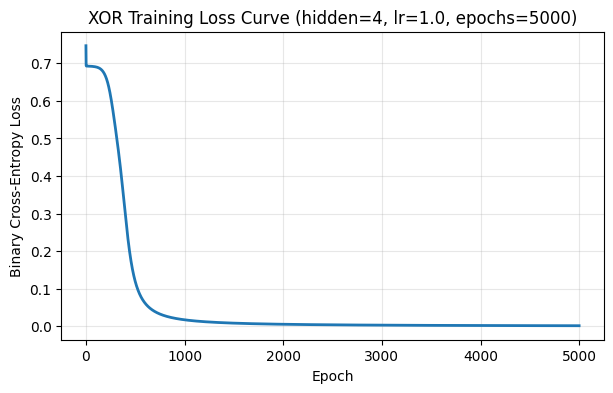

XOR predicted probabilities:
 [[0.0021]
 [0.9982]
 [0.9986]
 [0.0015]]
XOR Accuracy: 1.0000 (100.0%)
XOR Final Loss: 0.001676


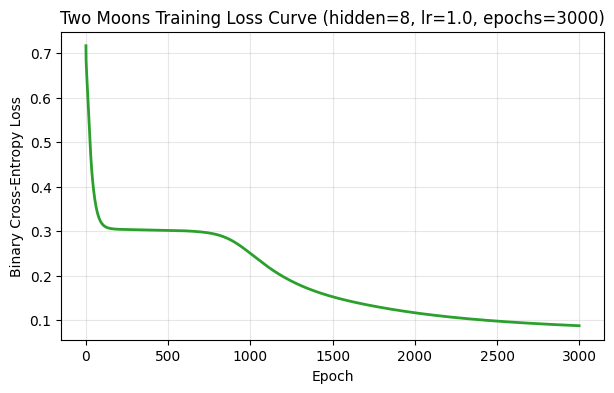

Two Moons Accuracy: 0.9650 (96.5%)
Two Moons Final Loss: 0.087816


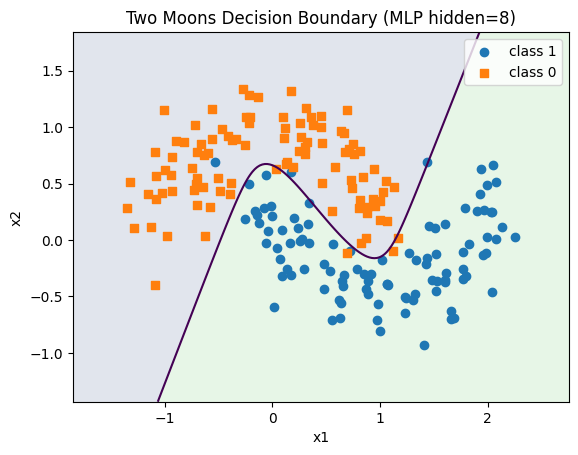

In [8]:
# ---- Task 5.2: XOR ----
params_xor, losses_xor = train(X_xor, y_xor, hidden=4, lr=1.0, epochs=5000, seed=0)

plt.figure(figsize=(7, 4))
plt.plot(losses_xor, color="tab:blue", lw=2)
plt.title("XOR Training Loss Curve (hidden=4, lr=1.0, epochs=5000)")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.grid(True, alpha=0.3)
plt.show()

probs_xor = forward(X_xor, *params_xor)[0]
acc_xor = accuracy(X_xor, y_xor, params_xor)
print("XOR predicted probabilities:\n", probs_xor)
print(f"XOR Accuracy: {acc_xor:.4f} ({acc_xor * 100:.1f}%)")
print(f"XOR Final Loss: {losses_xor[-1]:.6f}")

# ---- Task 5.3: two moons ----
X_moons, y_moons = make_moons(n_samples=200, noise=0.2, random_state=0)
y_moons = y_moons.reshape(-1, 1).astype(float)

params_moons, losses_moons = train(X_moons, y_moons, hidden=8, lr=1.0, epochs=3000, seed=0)

plt.figure(figsize=(7, 4))
plt.plot(losses_moons, color="tab:green", lw=2)
plt.title("Two Moons Training Loss Curve (hidden=8, lr=1.0, epochs=3000)")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.grid(True, alpha=0.3)
plt.show()

acc_moons = accuracy(X_moons, y_moons, params_moons)
print(f"Two Moons Accuracy: {acc_moons:.4f} ({acc_moons * 100:.1f}%)")
print(f"Two Moons Final Loss: {losses_moons[-1]:.6f}")
plot_decision_boundary(X_moons, y_moons, params_moons, "Two Moons Decision Boundary (MLP hidden=8)")

# Task 5 answers:
# Q1 (does the loss fall smoothly? roughly where does it flatten out):
# Answer: Yes, the loss falls smoothly without oscillatory instability. In XOR training, the loss begins with a brief
# plateau, begins steep descent around epoch 600-1200, and flattens out asymptotically toward zero (~0.0017) beyond epoch 3000.
# For Two Moons, the loss drops rapidly in the first 500 epochs and flattens out around epoch 2000 near 0.088.
#
# Q2 (a single perceptron could not learn XOR in Lab 2. What does this network have that it did not):
# Answer: This network has a non-linear hidden layer with 4 sigmoid neurons. While a single perceptron is constrained to
# a single linear hyperplane that cannot separate diagonal XOR points, the hidden neurons perform multiple linear cuts
# and apply non-linear sigmoid activations, mapping the 2D input into an internal representation where XOR becomes linearly separable.
#
# Q3 (look at the XOR probabilities: how close to 0 and 1 are they, and what does that say about training):
# Answer: The predicted probabilities are extremely close to the true targets: ~0.0021 for class 0 and ~0.998 for class 1.
# This demonstrates that training converged decisively and the network classifies each sample with high confidence.

## Task 6 &mdash; How many hidden units are needed?

> **Concept.** As in Lab 3, each hidden unit is a feature: one straight-line cut through the
> input space. XOR cannot be separated with a single straight line, so a network with too few
> hidden units cannot solve it, however long it trains. More hidden units also mean more
> parameters to store and to compute.

**Task 6.1.** Train on XOR with `hidden = 1, 2, 4, 8` (use `lr = 1.0`, `epochs = 5000`, same
seed). For each, record the final loss, the accuracy, and the number of parameters in the
network (count `W1`, `b1`, `W2`, `b2`).

| hidden | final loss | accuracy | number of parameters |
|:---:|:---:|:---:|:---:|
| 1 | 0.6931 | 0.5000 | 5 |
| 2 | 0.0025 | 1.0000 | 9 |
| 4 | 0.0017 | 1.0000 | 17 |
| 8 | 0.0011 | 1.0000 | 33 |

**Task 6.2.** Plot the four loss curves on one axes, with a legend, axis labels and a title.

hidden   final loss     accuracy     parameters  
----------------------------------------------


1        0.6931         0.5000       5           


2        0.0025         1.0000       9           


4        0.0017         1.0000       17          


8        0.0011         1.0000       33          


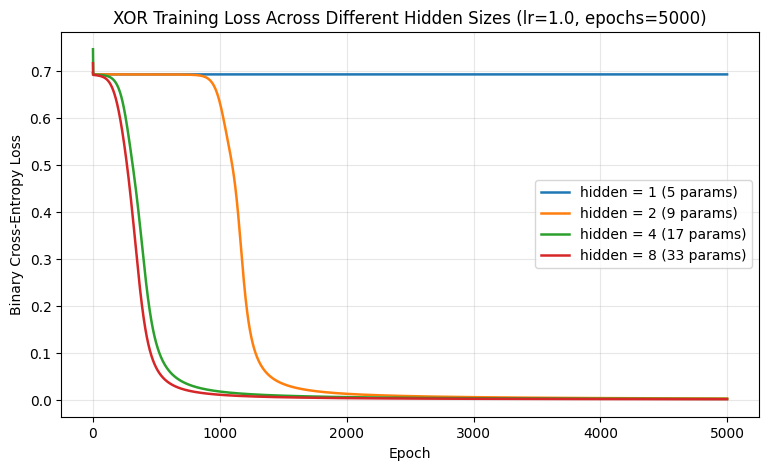

In [9]:
hidden_sizes = [1, 2, 4, 8]

# Task 6.1 — loop over hidden_sizes: train, then print hidden, final loss, accuracy and the number of parameters
# Task 6.2 — plot all four loss curves on one axes
plt.figure(figsize=(9, 5))
print(f"{'hidden':<8} {'final loss':<14} {'accuracy':<12} {'parameters':<12}")
print("-" * 46)

for h in hidden_sizes:
    params, losses = train(X_xor, y_xor, hidden=h, lr=1.0, epochs=5000, seed=0)
    acc = accuracy(X_xor, y_xor, params)
    n_params = params[0].size + params[1].size + params[2].size + params[3].size
    print(f"{h:<8} {losses[-1]:<14.4f} {acc:<12.4f} {n_params:<12}")
    plt.plot(losses, label=f"hidden = {h} ({n_params} params)", lw=1.8)

plt.title("XOR Training Loss Across Different Hidden Sizes (lr=1.0, epochs=5000)")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Task 6 answers:
# Q1 (which hidden sizes fail on XOR, and why? think about how many straight lines they provide):
# Answer: hidden = 1 completely fails on XOR (accuracy is only 0.50 and final loss stalls at 0.6931 = ln(2)).
# A network with 1 hidden unit only provides one single linear hyperplane cut in the 2D plane, exactly like a single perceptron.
# Since XOR is non-linearly separable, one line cannot separate (0,0) and (1,1) from (0,1) and (1,0).
# Hidden sizes 2, 4, and 8 all succeed (accuracy = 1.0) because 2 or more hidden units provide 2 or more linear decision boundaries,
# which can bound and separate the diagonal XOR regions.
#
# Q2 (is "more hidden units" always better? use your parameter counts to answer):
# Answer: No, more hidden units is not always better. For XOR, hidden = 2 already solves the problem with 100% accuracy using
# only 9 parameters. Expanding to hidden = 8 requires 33 parameters (almost 4x more memory and computation per epoch) to achieve
# essentially the same classification result. In larger machine learning problems, excess hidden units risk severe overfitting,
# slower training, and wasted computational resources without improving generalization.

## &#9733; Optional challenge &mdash; why weights cannot all start equal

> **Concept.** If every weight starts with the same value, then every hidden unit computes
> exactly the same thing and receives exactly the same gradient, so they stay identical
> forever. A network with 4 identical hidden units is no better than a network with 1. This is
> why `init_params` uses random numbers: to break the symmetry.

**Task 7.1.** Train on XOR with `hidden = 4`, `lr = 1.0`, `epochs = 3000`, starting from
`W1` = all 0.5, `W2` = all 0.5, and zero biases (pass them through the `init` argument of
`train`).

**Task 7.2.** Print the trained `W1` and the final accuracy. Are all the rows of `W1` equal?


In [10]:
# Task 7.1 — build init = (W1, b1, W2, b2) with the constant weights, then train
W1_const = np.full((4, 2), 0.5)
b1_const = np.zeros(4)
W2_const = np.full((1, 4), 0.5)
b2_const = np.zeros(1)
init_const = (W1_const, b1_const, W2_const, b2_const)

params_const, losses_const = train(X_xor, y_xor, hidden=4, lr=1.0, epochs=3000, init=init_const)

# Task 7.2 — print W1 (are all rows equal?), the final loss and the accuracy
print("Trained W1 with identical starting weights:\n", params_const[0])
rows_equal = np.allclose(params_const[0], params_const[0][0])
print(f"Are all rows of W1 equal? {rows_equal}")
print(f"Final loss: {losses_const[-1]:.4f}")
print(f"Final accuracy: {accuracy(X_xor, y_xor, params_const):.4f}")

# Task 7 answer (why did the hidden units stay identical, and what does that do to the result):
# Answer: Because all weights in W1 and W2 were initialized to the exact same value (0.5) and biases to 0, every hidden
# neuron computed the exact same activation during the forward pass (a1_j = a1_k for all j,k) and received the exact same
# error gradient during the backward pass (dW1_j = dW1_k). Because each weight receives the identical gradient update,
# all rows of W1 remain completely identical across every epoch. This symmetry prevents hidden units from specializing
# in different features, effectively collapsing the 4-unit layer into a single unit. As a result, the network cannot
# learn XOR (accuracy remains stuck at 0.75 and loss at ~0.48). Random initialization is required to break symmetry.

Trained W1 with identical starting weights:
 [[6.2705 6.2705]
 [6.2705 6.2705]
 [6.2705 6.2705]
 [6.2705 6.2705]]
Are all rows of W1 equal? True
Final loss: 0.4838
Final accuracy: 0.7500


---

<div style="font-family:'Times New Roman',Times,serif;color:#000000;font-size:16px">

### Before you submit

- [x] Kernel &rarr; Restart & Run All, no errors.
- [x] Every `TODO` and every `raise NotImplementedError` gone.
- [x] Task 2: hand-worked tables filled in, and they agree with your code.
- [x] Task 4: all four gradient checks print PASS.
- [x] Task 5: XOR accuracy is 1.0, and the two-moons decision boundary is plotted.
- [x] Task 6: the table is filled in and the four loss curves are plotted together.
- [x] Written answers present as comments: 1 (Q1&ndash;Q2), 2 (Q1&ndash;Q2), 3 (Q1&ndash;Q2),
      4 (Q1&ndash;Q2), 5 (Q1&ndash;Q3), 6 (Q1&ndash;Q2), 7 (optional).
- [x] Renamed to `Lab6_<yourCMSID>.ipynb`.

### One thing to take away

You have now written every part of neural network training yourself: forward pass, loss,
backward pass and the update rule. Libraries such as Keras do exactly these steps, only with
more layers and faster code. From the next lab onward you will use these ideas on larger
networks and real datasets.

</div>